# Ejercicio 05 — Recomendador MovieLens: popularidad, contenido, factorización e híbrido

**Curso:** INF-8239 Ciencia de Datos II · **Unidad 3** · LAB08 + LAB09

Este notebook **no vuelve a entrenar nada**: lee los resultados que ya produjeron
`scripts/lab08_content.py` y `scripts/lab09_hybrid.py` (carpeta `reports/`) y los presenta con tablas y gráficas.
Así, todo lo que se ve aquí sale de los archivos guardados en el repositorio.

**Pregunta:** ¿qué estrategia de recomendación conviene para una plataforma de películas, si importan no solo los aciertos
sino también la variedad de lo recomendado y el costo?

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

REPORTS = next(p for p in (Path("reports"), Path("../reports")) if p.exists())
K = 10
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print("Leyendo resultados desde:", REPORTS.resolve())

Leyendo resultados desde: C:\Users\PC\Downloads\INF8239_U03_Recomendadores_Proyecto_Base_uv\INF8239_U03_Recomendadores_Proyecto_Base\reports


## 1. Datos y procedencia
MovieLens Latest Small (GroupLens). El dataset **no se redistribuye** en este repositorio; solo se guarda su procedencia.

In [2]:
provenance_path = REPORTS / "dataset_provenance.json"
if provenance_path.exists():
    provenance = json.loads(provenance_path.read_text(encoding="utf-8"))
    display(pd.Series(provenance, name="valor").to_frame())
else:
    print("No se encontró dataset_provenance.json")

,valor
url,https://files.grouplens.org/datasets/movielens...
downloaded_utc,2026-10-15 02:21:30
sha256_of_zip,696d65a3dfceac7c45750ad32df2c259311949efec81f0...
ratings_rows,100836
movies_rows,9742
users,610


## 2. Partición temporal y auditoría
La **última valoración de cada usuario** se reserva para evaluar (corte temporal "leave-last-out"); todo lo demás es entrenamiento.
Se mide si la película reservada aparece en el Top-10 recomendado.

In [3]:
audit = json.loads((REPORTS / "lab09_audit.json").read_text(encoding="utf-8"))
shown = {k: v for k, v in audit.items() if k not in ("cold_start", "environment", "arguments")}
display(pd.Series(shown, name="valor").to_frame())
print("Argumentos de la corrida:", audit.get("arguments"))
print("Entorno:", audit.get("environment"))

,valor
users,610
evaluable_users,587
users_with_cold_item_target,23
users_with_tied_last_timestamp,94
train_ratings,100226
candidate_universe_items,9701
k,10
hybrid_candidate_pool,100
tie_break_rule,a igual puntuación gana el ítem de menor índice
popularity_smoothing_m,12.0


Argumentos de la corrida: {'factors': [10, 20, 40], 'seeds': [42, 43, 44], 'epochs': 12, 'alphas': [0.25, 0.75], 'max_users': 0}
Entorno: {'python': '3.12.14', 'os': 'Windows-11-10.0.26300-SP0', 'processor': 'Intel64 Family 6 Model 122 Stepping 8, GenuineIntel', 'numpy': '2.5.3', 'pandas': '2.3.3'}


## 3. Comparación de métodos (promedio de semillas)

In [4]:
summary = pd.read_csv(REPORTS / "lab09_summary.csv")

def label(row):
    text = row["method"]
    if pd.notna(row["factors"]):
        text += f" f{int(row['factors'])}"
    if pd.notna(row["alpha"]):
        text += f" a{row['alpha']:g}"
    return text

summary["etiqueta"] = summary.apply(label, axis=1)
columns = ["etiqueta", f"hit_rate@{K}", f"ndcg@{K}", "mrr", f"coverage@{K}", f"diversity@{K}",
           f"head_share@{K}", "rmse", "train_seconds", "factor_memory_kb", "is_pareto"]
display(summary[columns].round(4))

,etiqueta,hit_rate@10,ndcg@10,mrr,coverage@10,diversity@10,head_share@10,rmse,train_seconds,factor_memory_kb,is_pareto
0,popularity_count,0.0443,0.0202,0.0190,0.0124,0.7878,1.0000,NaN,0.0290,NaN,True
1,hybrid f20 a0.75,0.0392,0.0184,0.0161,0.0763,0.7610,0.8799,1.0248,73.2912,1611.0938,False
2,mf f20,0.0386,0.0185,0.0172,0.0742,0.7959,0.8818,1.0248,73.0938,1611.0938,False
3,hybrid f40 a0.75,0.0341,0.0161,0.0143,0.0983,0.7621,0.8499,1.0189,67.6351,3222.1875,False
4,mf f10,0.0341,0.0145,0.0138,0.0505,0.7896,0.9080,1.0303,82.8656,805.5469,False
5,popularity_weighted,0.0324,0.0168,0.0166,0.0063,0.7179,0.9911,NaN,0.0290,NaN,False
6,mf f40,0.0312,0.0156,0.0154,0.0977,0.7971,0.8514,1.0189,67.4377,3222.1875,False
7,hybrid f10 a0.75,0.0307,0.0138,0.0135,0.0531,0.7562,0.9060,1.0303,83.0630,805.5469,False
8,hybrid f20 a0.25,0.0284,0.0122,0.0117,0.1041,0.5350,0.8247,1.0248,73.2912,1611.0938,False
9,hybrid f10 a0.25,0.0273,0.0110,0.0108,0.0817,0.5404,0.8674,1.0303,83.0630,805.5469,False


### 3.1 ¿Cuánta confianza dan las diferencias?
Con pocos aciertos, las diferencias pequeñas pueden ser azar. Se calcula un intervalo aproximado del 95 % del HitRate
con la fórmula binomial: `1.96 · √(p(1−p)/n)`, donde `n` es el número de usuarios evaluables.
La desviación entre semillas **no** sirve para esto, porque solo mide la variación del entrenamiento y no la de los usuarios.

,etiqueta,hit_rate@10,hit_margin95,aciertos_aprox
0,popularity_count,0.0443,0.0166,26.0
1,hybrid f20 a0.75,0.0392,0.0157,23.0
2,mf f20,0.0386,0.0156,22.7
3,hybrid f40 a0.75,0.0341,0.0147,20.0
4,mf f10,0.0341,0.0147,20.0
5,popularity_weighted,0.0324,0.0143,19.0
6,mf f40,0.0312,0.0141,18.3
7,hybrid f10 a0.75,0.0307,0.0139,18.0
8,hybrid f20 a0.25,0.0284,0.0134,16.7
9,hybrid f10 a0.25,0.0273,0.0132,16.0


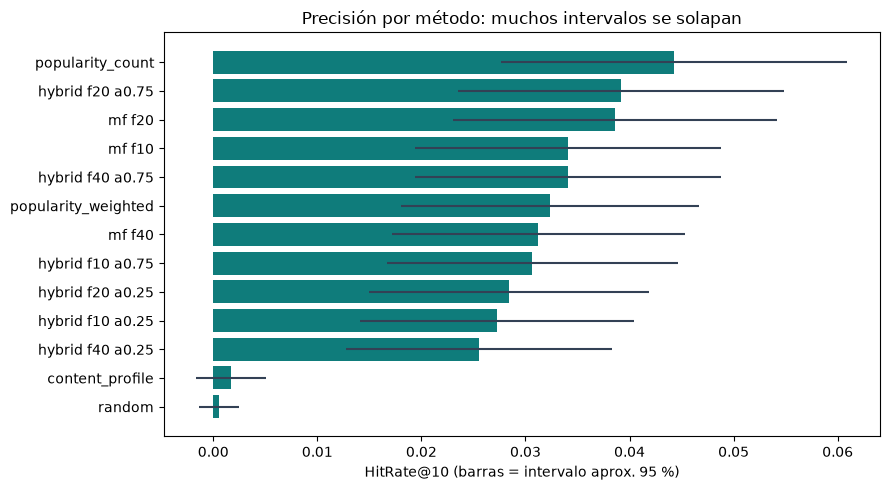

In [5]:
n_users = audit["evaluable_users"]
summary["hit_margin95"] = 1.96 * np.sqrt(summary[f"hit_rate@{K}"] * (1 - summary[f"hit_rate@{K}"]) / n_users)
summary["aciertos_aprox"] = (summary[f"hit_rate@{K}"] * n_users).round(1)
display(summary[["etiqueta", f"hit_rate@{K}", "hit_margin95", "aciertos_aprox"]].round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ordered = summary.sort_values(f"hit_rate@{K}")
ax.barh(ordered["etiqueta"], ordered[f"hit_rate@{K}"], xerr=ordered["hit_margin95"], color="#0f7c7b", ecolor="#334155")
ax.set_xlabel(f"HitRate@{K} (barras = intervalo aprox. 95 %)")
ax.set_title("Precisión por método: muchos intervalos se solapan")
fig.tight_layout()
plt.show()

## 4. Más allá de la precisión: cobertura y concentración en lo popular
Un recomendador que solo sugiere lo más visto acierta algo, pero ofrece lo mismo a todos.

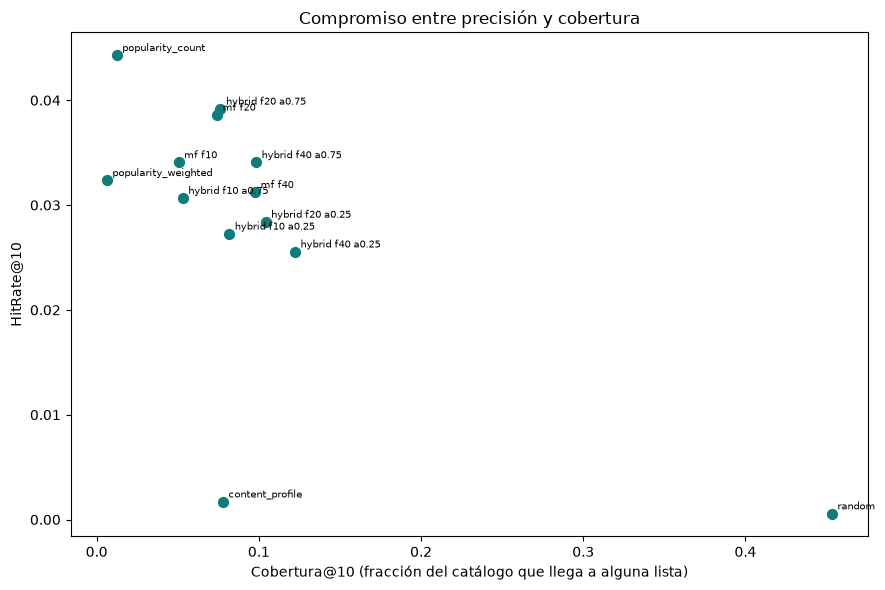

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(summary[f"coverage@{K}"], summary[f"hit_rate@{K}"], color="#0f7c7b", s=50)
for _, row in summary.iterrows():
    ax.annotate(row["etiqueta"], (row[f"coverage@{K}"], row[f"hit_rate@{K}"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set_xlabel(f"Cobertura@{K} (fracción del catálogo que llega a alguna lista)")
ax.set_ylabel(f"HitRate@{K}")
ax.set_title("Compromiso entre precisión y cobertura")
fig.tight_layout()
plt.show()

## 5. RMSE frente a calidad del ranking (factorización)
Predecir bien la nota no es lo mismo que ordenar bien el Top-10.

,factors,rmse,hit_rate@10,ndcg@10,factor_memory_kb,train_seconds
4,10.0,1.0303,0.0341,0.0145,805.5469,82.8656
2,20.0,1.0248,0.0386,0.0185,1611.0938,73.0938
6,40.0,1.0189,0.0312,0.0156,3222.1875,67.4377


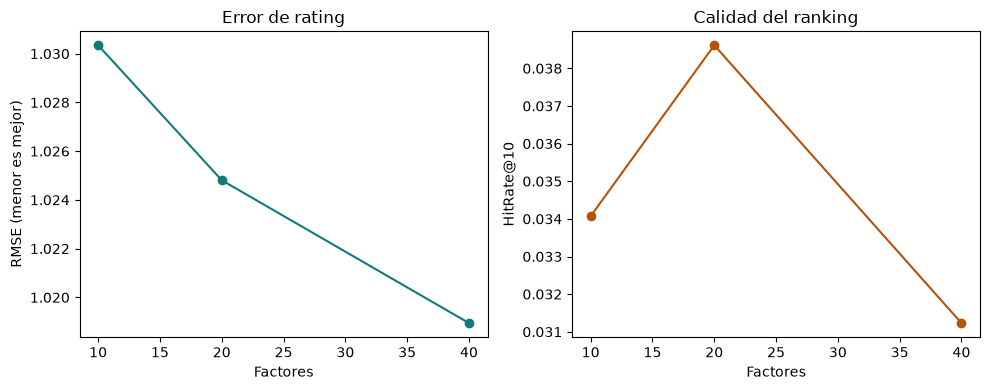

In [7]:
mf = summary[summary["method"].eq("mf")].sort_values("factors")
display(mf[["factors", "rmse", f"hit_rate@{K}", f"ndcg@{K}", "factor_memory_kb", "train_seconds"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(mf["factors"], mf["rmse"], marker="o", color="#0f7c7b")
axes[0].set_xlabel("Factores"); axes[0].set_ylabel("RMSE (menor es mejor)"); axes[0].set_title("Error de rating")
axes[1].plot(mf["factors"], mf[f"hit_rate@{K}"], marker="o", color="#b45309")
axes[1].set_xlabel("Factores"); axes[1].set_ylabel(f"HitRate@{K}"); axes[1].set_title("Calidad del ranking")
fig.tight_layout()
plt.show()

## 6. Frontera de Pareto (calidad vs. tiempo de ajuste)
Se excluye el azar, que es solo un piso de referencia.

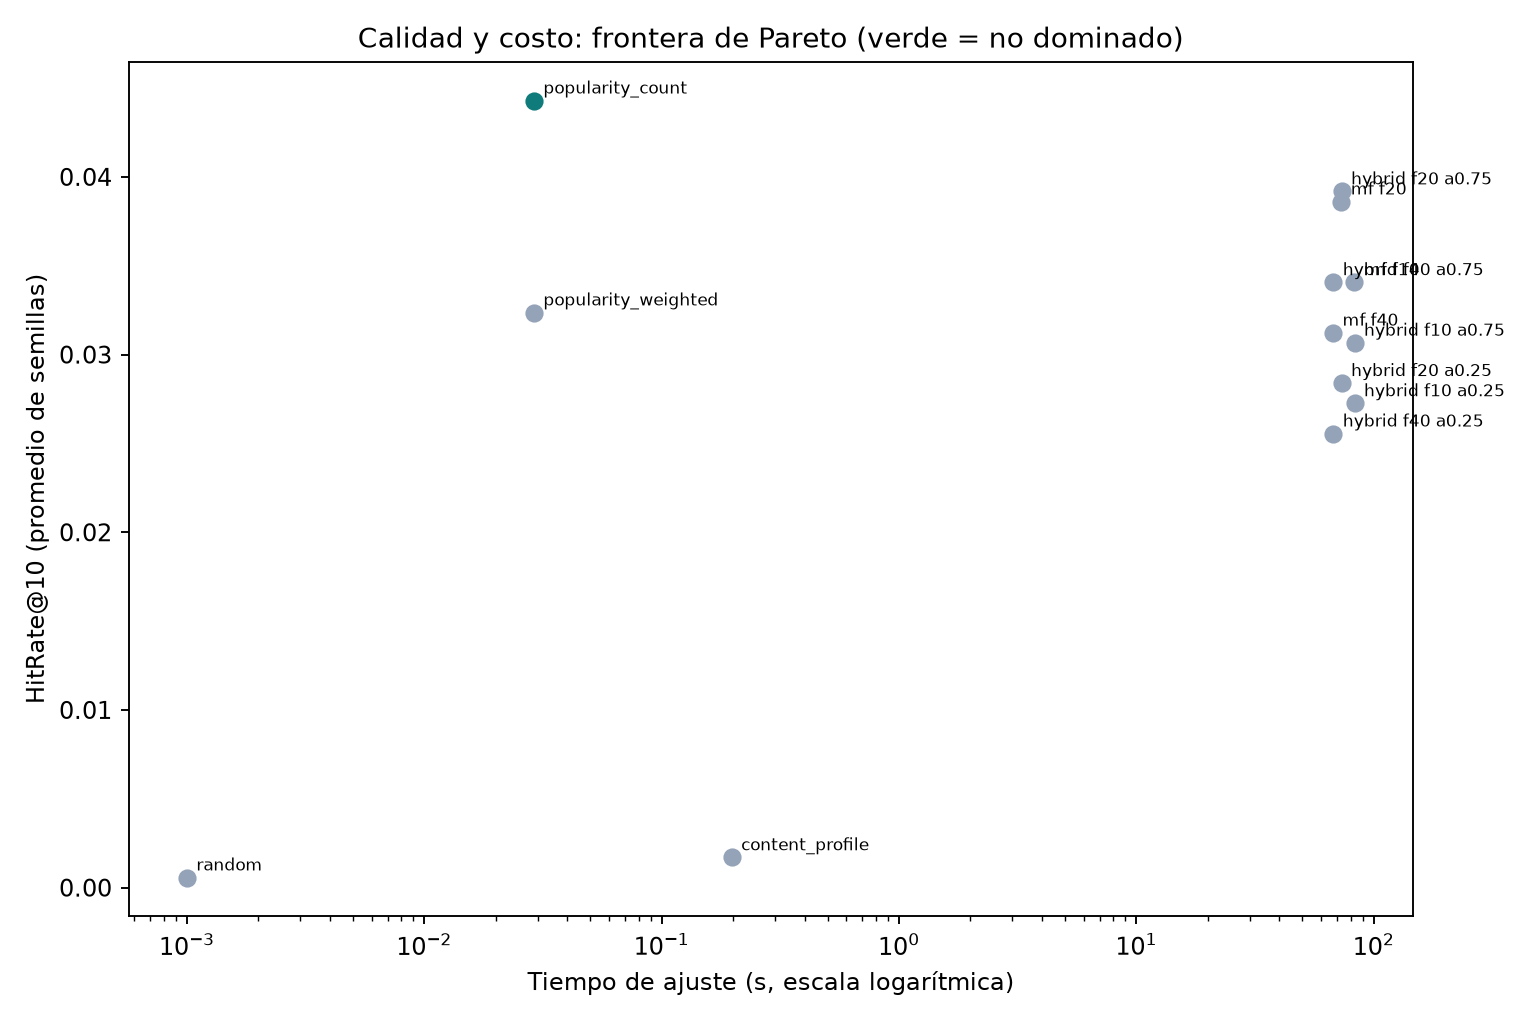

,etiqueta,hit_rate@10,train_seconds
0,popularity_count,0.044293,0.028968


In [8]:
display(Image(filename=str(REPORTS / "pareto_hit_vs_time.png")))
display(summary.loc[summary["is_pareto"], ["etiqueta", f"hit_rate@{K}", "train_seconds"]])

**Lectura honesta:** el eje de costo es el *tiempo de ajuste*, y la popularidad no se entrena, por eso domina la frontera.
Esto no significa que sea la mejor opción de producto: cubre una fracción mínima del catálogo y recomienda lo mismo a todos.
El tiempo medido también tiene ruido de la máquina (10 factores tardó más que 40), así que no se interpreta como una ley.

## 7. Usuarios nuevos (arranque en frío)
Se retira por completo a un 10 % de usuarios del entrenamiento. La factorización no puede puntuarlos.

In [9]:
cold = {k: v for k, v in audit["cold_start"].items() if k != "note"}
display(pd.DataFrame(cold).T.round(4))
print(audit["cold_start"]["note"])
n_cold = int(next(iter(cold.values()))["users"])
print(f"Cuidado: son solo {n_cold} usuarios; un HitRate de 0.034 equivale a ~{round(0.0339 * n_cold)} aciertos.")

,users,hit_rate@10,ndcg@10,mrr
fallback_0_ratings,59.0,0.0339,0.0124,0.0108
popularity_after_5_ratings,59.0,0.0339,0.0126,0.0111
content_after_5_ratings,59.0,0.0000,0.0000,0.0014
random,59.0,0.0000,0.0000,0.0004


Usuarios retirados por completo del entrenamiento. La factorización no puede puntuarlos; se compara el respaldo de popularidad con un perfil de contenido de 5 valoraciones.
Cuidado: son solo 59 usuarios; un HitRate de 0.034 equivale a ~2 aciertos.


## 8. Tres perfiles de usuario

In [10]:
profiles = pd.read_csv(REPORTS / "lab09_profiles.csv")
for (name, method), group in profiles.groupby(["profile", "method"], sort=False):
    print(f"\n== {name} · {method} · historial={group['history_size'].iloc[0]} ==")
    display(group[["rank", "title", "genres"]].reset_index(drop=True))
print("\nCoincidencia entre listas de alpha extremos:", audit.get("profile_overlap_between_first_and_last_alpha"))


== historial_amplio · híbrido alpha=0.25 · historial=2697 ==


,rank,title,genres
0,1,Intouchables (2011),Comedy|Drama
1,2,12 Angry Men (1957),Drama
2,3,"Philadelphia Story, The (1940)",Comedy|Drama|Romance
3,4,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War
4,5,Modern Times (1936),Comedy|Drama|Romance
5,6,My Life as a Dog (Mitt liv som hund) (1985),Comedy|Drama
6,7,Manhattan (1979),Comedy|Drama|Romance
7,8,"King of Comedy, The (1983)",Comedy|Drama
8,9,City Lights (1931),Comedy|Drama|Romance
9,10,Man Bites Dog (C'est arrivé près de chez vous)...,Comedy|Crime|Drama|Thriller



== historial_amplio · híbrido alpha=0.75 · historial=2697 ==


,rank,title,genres
0,1,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War
1,2,12 Angry Men (1957),Drama
2,3,My Fair Lady (1964),Comedy|Drama|Musical|Romance
3,4,Intouchables (2011),Comedy|Drama
4,5,Annie Hall (1977),Comedy|Romance
5,6,"Philadelphia Story, The (1940)",Comedy|Drama|Romance
6,7,Psycho (1960),Crime|Horror
7,8,"Lives of Others, The (Das leben der Anderen) (...",Drama|Romance|Thriller
8,9,Ben-Hur (1959),Action|Adventure|Drama
9,10,Shutter Island (2010),Drama|Mystery|Thriller



== historial_pequeno · híbrido alpha=0.25 · historial=19 ==


...


== historial_pequeno · híbrido alpha=0.75 · historial=19 ==


,rank,title,genres
0,1,"Godfather, The (1972)",Crime|Drama
1,2,Annie Hall (1977),Comedy|Romance
2,3,Apocalypse Now (1979),Action|Drama|War
3,4,Slumdog Millionaire (2008),Crime|Drama|Romance
4,5,Rocky (1976),Drama
5,6,Match Point (2005),Crime|Drama|Romance
6,7,Goodfellas (1990),Crime|Drama
7,8,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi
8,9,Punch-Drunk Love (2002),Comedy|Drama|Romance
9,10,Notting Hill (1999),Comedy|Romance



== usuario_nuevo · respaldo: popularidad por cantidad (no personalizada) · historial=0 ==


,rank,title,genres
0,1,Forrest Gump (1994),Comedy|Drama|Romance|War
1,2,"Shawshank Redemption, The (1994)",Crime|Drama
2,3,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
3,4,"Matrix, The (1999)",Action|Sci-Fi|Thriller
4,5,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
5,6,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
6,7,Braveheart (1995),Action|Drama|War
7,8,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
8,9,Terminator 2: Judgment Day (1991),Action|Sci-Fi
9,10,Fight Club (1999),Action|Crime|Drama|Thriller



Coincidencia entre listas de alpha extremos: {'historial_amplio': 0.4, 'historial_pequeno': 0.6}


Con `alpha = 0.25` (más peso al contenido) las listas se parecen más entre sí en género; con `alpha = 0.75` (más peso colaborativo)
aparece más variedad. El usuario nuevo recibe el respaldo de popularidad, que **no es personalizado** y así se rotula.

## 9. Decisión, evidencia y límites

**Configuración elegida:** híbrido con **20 factores y alpha = 0.75**, con **popularidad como respaldo para usuarios nuevos**.

**Evidencia a favor**
- Su HitRate (0.039) es estadísticamente indistinguible del mejor (popularidad, 0.044): la diferencia es de unos 3 usuarios sobre 587.
- Cubre unas 6 veces más catálogo que la popularidad (7.6 % frente a 1.2 %) y concentra menos sus listas en películas muy populares (88 % frente a 100 %).
- 20 factores fue el mejor tamaño en HitRate entre los probados y usa la mitad de memoria que 40.
- Alpha 0.25 perdió aciertos y diversidad de géneros.

**Lo que no se pudo demostrar**
- El híbrido **no superó** a la factorización sola (0.0392 frente a 0.0386) ni a la popularidad.
- La recomendación por contenido solo (géneros) casi no acierta (≈1 usuario).
- Los resultados de arranque en frío se basan en 59 usuarios (≈2 aciertos): son orientativos.

**Límites**
- Un solo corte temporal y 587 usuarios; sin intervalos por remuestreo de usuarios.
- Las valoraciones pasadas no miden satisfacción real: una película no valorada puede ser buena para el usuario.
- 12 épocas de SGD y una cuadrícula pequeña; el RMSE (≈1.02) podría mejorar con más ajuste.
- La popularidad en el historial puede reforzarse a sí misma (sesgo de popularidad) si las recomendaciones influyen en lo que luego se valora.